# Stochastic Dynamics of Epidemics: A Gillespie Simulation of the SIRD Model

Martina Balsamello, Matteo Zabban

## Introduction

Understanding epidemic dynamics requires not only deterministic models, such as the classical SIRD system of differential equations, but also stochastic approaches that account for randomness in transmission and recovery events.  
In this project, we develop and analyze a **stochastic SIRD model** using the **Gillespie algorithm** to simulate individual-level interactions within a finite population.  
Our goal is to:
- Compare stochastic trajectories with deterministic ODE solutions,
- Quantify variability across repeated realizations,
- Investigate how key parameters (infection rate, recovery rate, mortality rate, population size) affect epidemic outcomes such as peak size, extinction probability, and final epidemic size.  

The project aims to highlight the fundamental differences between deterministic and stochastic epidemic descriptions, emphasizing how randomness can shape outbreak dynamics even under identical average parameters.

### Imports

In [60]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from ipywidgets import interact, interact_manual, FloatSlider, IntSlider, Checkbox



rng = np.random.default_rng(seed=42)

## BASELINE MODEL

Simula una traiettoria SIRD con algoritmo di Gillespie (Direct Method).
 Reazioni:
      1) Infezione:  S + I -> 2I     (tasso: beta * S*I/N)
      2) Guarigione: I -> R          (tasso: gamma * I)
      3) Decesso:    I -> D          (tasso: mu * I)

Stop: I == 0 (stato assorbente) oppure t >= t_max.
Ritorna:
      T: array[float] tempi (monotoni, include t=0 e l’ultimo tempo)
      X: array[int] stato (S,I,R,D) agli stessi tempi di T

In [2]:
def gillespie_sird(S0, I0, R0, D0, beta, gamma, mu, t_max=np.inf, rng=None):

    if rng is None:
        rng = np.random.default_rng()

    N = S0 + I0 + R0 + D0
    t = 0.0
    S, I, R, D = int(S0), int(I0), int(R0), int(D0)

    T = [t]
    X = [(S, I, R, D)]

    while t < t_max:
        a1 = beta * S * I / N
        a2 = gamma * I
        a3 = mu * I
        a0 = a1 + a2 + a3

        if a0 <= 0.0:
            break

        tau = rng.exponential(1.0 / a0)

        if t + tau > t_max:
            t = float(t_max)
            T.append(t)
            X.append((S, I, R, D)) 
            break

        t += tau

        r = rng.random() * a0  
        if r < a1:
            if S > 0:
                S -= 1
                I += 1
        elif r < a1 + a2:
            if I > 0:
                I -= 1
                R += 1
        else:
            if I > 0:
                I -= 1
                D += 1

        T.append(t)
        X.append((S, I, R, D))

        if I == 0:
            break

    return np.array(T, dtype=float), np.array(X, dtype=int)


In [5]:
N     = 1000   # popolazione totale
S0, I0, R0, D0 = N-1, 1, 0, 0  

beta  = 0.30   # infection rate
gamma = 0.10   # recovery rate
mu    = 0.02   # mortality rate

t_max = 160.0

R0_basic = beta / (gamma + mu)
print(f"R0 (basic reproduction number) = {R0_basic:.2f}")
print(f"Initial state: S={S0}, I={I0}, R={R0}, D={D0}, N={N}")

R0 (basic reproduction number) = 2.50
Initial state: S=999, I=1, R=0, D=0, N=1000


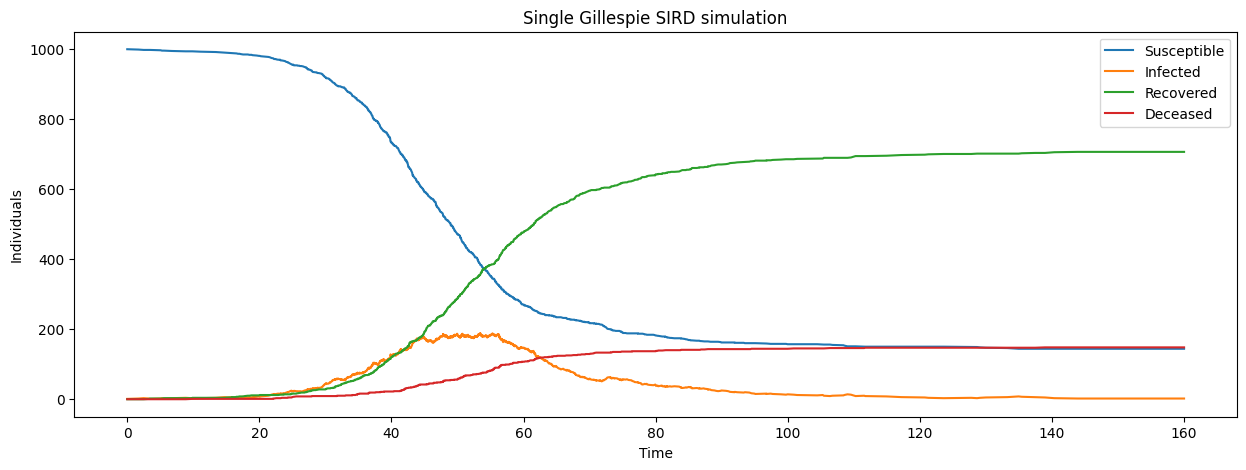

In [45]:
T, X = gillespie_sird(S0, I0, R0, D0, beta, gamma, mu, t_max=t_max, rng=rng)

S, I, R, D = X.T

plt.figure(figsize=(15,5))
plt.plot(T, S, label="Susceptible")
plt.plot(T, I, label="Infected")
plt.plot(T, R, label="Recovered")
plt.plot(T, D, label="Deceased")
plt.xlabel("Time")
plt.ylabel("Individuals")
plt.title("Single Gillespie SIRD simulation")
plt.legend()
plt.show()

In [ ]:
def simulate_and_plot_single(beta=0.30, gamma=0.10, mu=0.02,
                             N=1000, I0=1, t_max=160, seed=42):
    I0 = max(1, int(I0))
    N = int(max(N, I0+1))
    S0, R0, D0 = N - I0, 0, 0

    R0_basic = beta / (gamma + mu)
    rng = np.random.default_rng(seed)

    T, X = gillespie_sird(S0, I0, R0, D0, beta, gamma, mu, t_max=t_max, rng=rng)
    S, I, R, D = X.T

    plt.figure(figsize=(15,5))
    plt.plot(T, S, label="Susceptible")
    plt.plot(T, I, label="Infected")
    plt.plot(T, R, label="Recovered")
    plt.plot(T, D, label="Deceased")
    plt.xlabel("Time"); plt.ylabel("Individuals")
    plt.title(f"Single Gillespie SIRD — R0 = {R0_basic:.2f}")
    plt.legend()
    plt.show()

# sliders
interact(
    simulate_and_plot_single,
    beta=FloatSlider(min=0.01, max=1.0, step=0.01, value=0.30, description="β"),
    gamma=FloatSlider(min=0.01, max=1.0, step=0.01, value=0.10, description="γ"),
    mu=FloatSlider(min=0.00, max=0.30, step=0.005, value=0.02, description="μ"),
    N=IntSlider(min=100, max=10000, step=100, value=1000, description="N"),
    I0=IntSlider(min=1, max=50, step=1, value=1, description="I₀"),
    t_max=IntSlider(min=30, max=365, step=5, value=160, description="t_max")
);


interactive(children=(FloatSlider(value=0.3, description='β', max=1.0, min=0.01, step=0.01), FloatSlider(value…

## ANALISI STATISTICA 

In [51]:
def step_hold_resample(T, Y, t_grid):
    T = np.asarray(T, float)
    Y = np.asarray(Y, int)
    t_grid = np.asarray(t_grid, float)

    idx = np.searchsorted(T, t_grid, side="right") - 1
    idx[idx < 0] = 0
    idx[idx >= len(T)] = len(T) - 1
    return Y[idx]


In [52]:
def run_many(n_runs=200, t_max=t_max, seed=42):
    rng_master = np.random.default_rng(seed)
    t_grid = np.arange(0, int(t_max)+1, 1.0)

    results = {"S": [], "I": [], "R": [], "D": []}
    for _ in range(n_runs):
        rng = np.random.default_rng(rng_master.integers(0, 2**31-1))
        T, X = gillespie_sird(S0, I0, R0, D0, beta, gamma, mu, t_max=t_max, rng=rng)
        Xg = step_hold_resample(T, X, t_grid)
        for k, col in zip(results.keys(), Xg.T):
            results[k].append(col)

    def stats(A):
        A = np.vstack(A)
        mean = A.mean(axis=0)
        lo, hi = np.percentile(A, [2.5, 97.5], axis=0)
        return mean, lo, hi

    out = {k: stats(v) for k, v in results.items()}
    out["t"] = t_grid
    return out

many = run_many(n_runs=200, t_max=t_max, seed=42)
print("Simulations complete.")


Simulations complete.


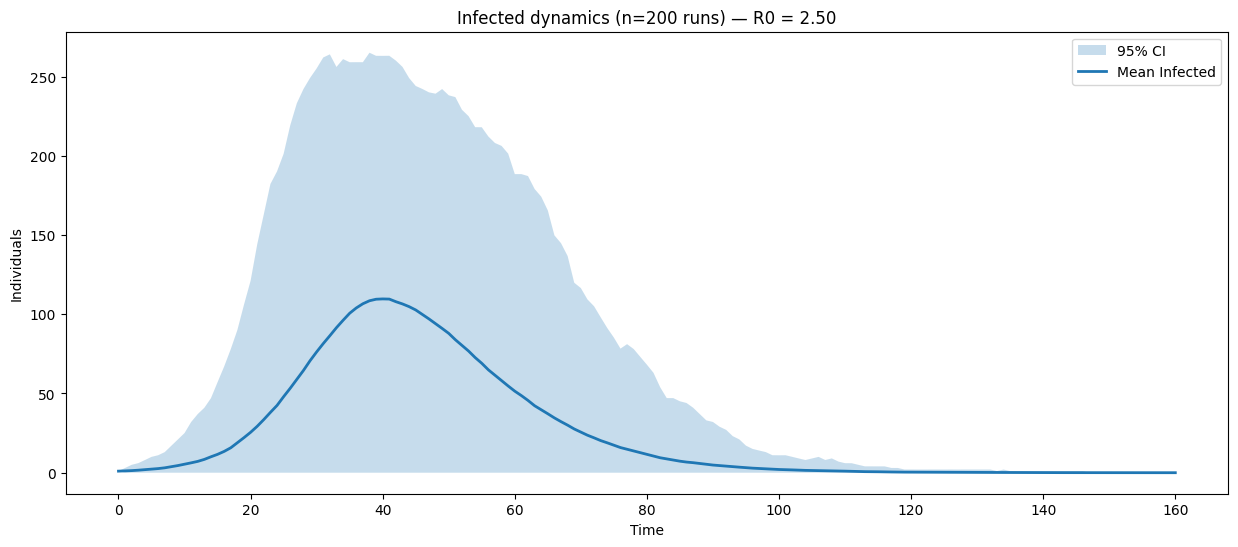

In [56]:
t = many["t"]
I_mean, I_lo, I_hi = many["I"]

plt.figure(figsize=(15,6))
plt.fill_between(t, I_lo, I_hi, alpha=0.25, label="95% CI")
plt.plot(t, I_mean, lw=2, label="Mean Infected")
plt.xlabel("Time"); plt.ylabel("Individuals")
plt.title(f"Infected dynamics (n=200 runs) — R0 = {beta/(gamma+mu):.2f}")
plt.legend(); plt.show()


In [ ]:
def compute_many_stats(beta, gamma, mu, N, I0, t_max, n_runs):
    t_grid = np.arange(0, int(t_max)+1, 1.0)

    S0, R0, D0 = int(N - I0), 0, 0
    I_stack = []

    for _ in range(int(n_runs)):
        T, X = gillespie_sird(S0, I0, R0, D0, beta, gamma, mu, t_max=t_max, rng=rng)
        Xg = step_hold_resample(T, X, t_grid)
        I_stack.append(Xg[:,1])

    I = np.vstack(I_stack)
    I_mean = I.mean(axis=0)
    I_lo, I_hi = np.percentile(I, [2.5, 97.5], axis=0)
    return t_grid, I_mean, I_lo, I_hi

def plot_many(beta=0.30, gamma=0.10, mu=0.02,
              N=1000, I0=1, t_max=160, n_runs=100,
              show_title=True):
    t, I_mean, I_lo, I_hi = compute_many_stats(beta, gamma, mu, N, I0, t_max, n_runs)
    R0_basic = beta / (gamma + mu)

    plt.figure(figsize=(15,6))
    plt.fill_between(t, I_lo, I_hi, alpha=0.25, label="95% CI")
    plt.plot(t, I_mean, lw=2, label="Mean Infected")
    plt.xlabel("Time"); plt.ylabel("Individuals")
    if show_title:
        plt.title(f"Infected dynamics (n={int(n_runs)} runs) — R0 = {R0_basic:.2f}")
    plt.legend(); plt.show()

interact_manual(
    plot_many,
    beta=FloatSlider(min=0.01, max=1.0, step=0.01, value=0.30, description="β"),
    gamma=FloatSlider(min=0.01, max=1.0, step=0.01, value=0.10, description="γ"),
    mu=FloatSlider(min=0.00, max=0.30, step=0.005, value=0.02, description="μ"),
    N=IntSlider(min=100, max=10000, step=100, value=1000, description="N"),
    I0=IntSlider(min=1, max=50, step=1, value=1, description="I₀"),
    t_max=IntSlider(min=30, max=365, step=5, value=160, description="t_max"),
    n_runs=IntSlider(min=20, max=300, step=10, value=100, description="runs"),
    show_title=Checkbox(value=True, description="Title"),
);


interactive(children=(FloatSlider(value=0.3, description='β', max=1.0, min=0.01, step=0.01), FloatSlider(value…